# Robust PCA on a dance video

We film a dance with a fixed camera. We want to split every frame into two layers: the empty studio, and the dancers. We do it without drawing anything by hand and without a trained model. We only use the structure of the data.

The project has two parts. In part 1 we decompose the video with Robust PCA, a convex relaxation of a problem that is too hard to solve directly. In part 2 we use the dancers' silhouettes to score how close a learner's dance is to the reference.

The reference video is the CORTIS "GO" dance practice: https://www.youtube.com/watch?v=gSm-eTRl9JE

## 1. Setup

Here we load the code of the project. All the functions live in `src/rpca_dance/`. The notebook only calls them. All the settings (paths, frame size, λ values, seeds) live in `config.py`, at the root of the project.

The notebook sits in the `notebooks/` folder, so we first tell Python where the root of the project is. This assumes the notebook runs from its own folder, which is what VS Code and Jupyter do by default.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

import numpy as np

import config
from rpca_dance.baselines import classic_pca
from rpca_dance.operators import singular_value_threshold, soft_threshold
from rpca_dance.pipeline import simulation_grid
from rpca_dance.plots import (plot_history, plot_small_matrices, plot_soft_threshold_curve,
                              plot_solver_times, plot_success_maps, show_figure)
from rpca_dance.rpca import objective_never_increases, rpca_proximal_gradient
from rpca_dance.sdp_check import compare_with_cvxpy, time_both_solvers
from rpca_dance.simulation import relative_error, success_fraction, summarize_success
from rpca_dance.toy import make_toy_example, print_matrix, singular_values

FIGURES = config.RESULTS_DIR / "notebook"
print(f"Project root: {PROJECT_ROOT}")
print(f"Figures of this notebook: {FIGURES}")

Project root: /Users/alienorsabourdin/Desktop/DancerPCA
Figures of this notebook: /Users/alienorsabourdin/Desktop/DancerPCA/results/notebook


Python now finds `config.py` and the package `rpca_dance`. Every figure the notebook makes is saved in `results/notebook/` and shown below its cell. The long computations (the simulation grid, the video decompositions) were run once and saved in `results/`. The notebook loads them, so it runs in a few seconds.

## 2. The question and the model

Here we look at one frame of the reference video, and at the size of the matrix we build from the video. We keep 50 seconds of the video, from 0:24 to 1:14, because the camera does not move in this window.

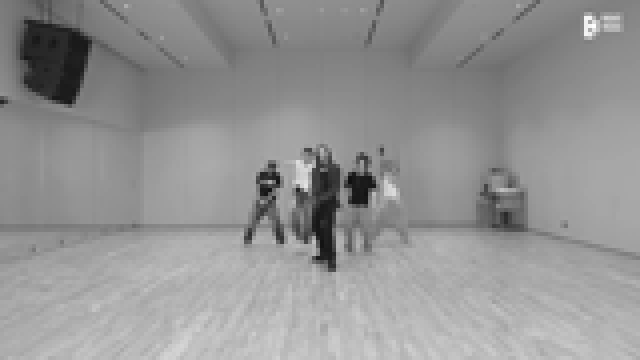

One frame: 160 x 90 = 14400 pixels
Number of frames: 50 s x 8 frames per second = 400
M has 14400 rows and 400 columns


In [2]:
show_figure(config.RESULTS_DIR / "sample_frame.png")

pixels_per_frame = config.FRAME_WIDTH * config.FRAME_HEIGHT
number_of_frames = int(config.DURATION_SECONDS * config.FRAMES_PER_SECOND)
print(f"One frame: {config.FRAME_WIDTH} x {config.FRAME_HEIGHT} = {pixels_per_frame} pixels")
print(f"Number of frames: {config.DURATION_SECONDS:.0f} s x {config.FRAMES_PER_SECOND} frames per second = {number_of_frames}")
print(f"M has {pixels_per_frame} rows and {number_of_frames} columns")

We see five dancers in an empty white studio. The image above is shown 4 times larger than what the algorithm uses.

Each frame is a small gray image of 160 × 90 pixels. We flatten it into one long column of 14,400 numbers. We put the 400 columns side by side. This gives us the matrix $M$, with 14,400 rows and 400 columns. Each column is one moment of the video, one eighth of a second after the previous one.

This matrix is the only thing the algorithm sees. It does not know what a dancer is. It only sees numbers between 0 (black) and 1 (white).

### The model

We write $M = L + S$.

$L$ is the background. The studio does not move, so every column of $L$ is almost the same image. Only the light can change a little. If every column is the same image times a brightness, $L$ has rank 1. A low rank means that a few images are enough to rebuild every frame.

$S$ is the dancers. They cover a small part of each frame. Everywhere else, $S$ is 0. We say that $S$ is sparse: most of its entries are exactly zero.

The ideal problem is

$$\min_{L,\,S} \ \operatorname{rank}(L) + \lambda \|S\|_0 \quad \text{subject to} \quad L + S = M.$$

Here $\operatorname{rank}(L)$ is the number of non-zero singular values of $L$. $\|S\|_0$ is the number of non-zero entries of $S$. $\lambda > 0$ sets the balance between the two terms.

This problem is NP-hard. Both terms count things, so they jump in steps. Nothing tells us in which direction to move to make them smaller.

### The convex relaxation

We replace each counting term by its convex envelope. The convex envelope of a function is the largest convex function that stays below it.

For vectors with entries between −1 and 1, the convex envelope of $\|x\|_0$ is the $\ell_1$ norm $\|x\|_1 = \sum_i |x_i|$. We count the entries in the first one, and we add up their sizes in the second one.

For matrices whose largest singular value is at most 1, the convex envelope of the rank is the nuclear norm $\|L\|_* = \sum_i \sigma_i(L)$, where the $\sigma_i(L)$ are the singular values of $L$. It is the same idea one level up: the rank counts the singular values, and the nuclear norm adds them up.

This gives Principal Component Pursuit (Candès, Li, Ma and Wright, 2011):

$$\min_{L,\,S} \ \|L\|_* + \lambda \|S\|_1 \quad \text{subject to} \quad L + S = M.$$

### The version we solve

A real video has noise, so $L + S = M$ is never exactly true for a clean $L$ and a clean $S$. We solve the penalized version instead:

$$\min_{L,\,S} \ F(L, S) = \tfrac{1}{2}\|M - L - S\|_F^2 + \lambda_1 \|L\|_* + \lambda_2 \|S\|_1.$$

The first term asks $L + S$ to stay close to $M$. $\|\cdot\|_F$ is the Frobenius norm: the square root of the sum of the squares of all the entries. $\lambda_1$ and $\lambda_2$ are the weights of the two penalties. A larger $\lambda_1$ pushes $L$ towards a lower rank. A larger $\lambda_2$ pushes $S$ towards fewer non-zeros.

All three terms are convex, so $F$ is convex. Every local minimum is a global minimum. This is the problem we solve in the whole project.

## 3. The two building blocks

Our algorithm, proximal gradient descent, needs one tool for each penalty: its proximal operator. The proximal operator of a function $g$ with threshold $\tau$ takes a point $X$. It returns the point that stays close to $X$ while keeping $g$ small:

$$\operatorname{prox}_{\tau g}(X) = \arg\min_Z \ \tfrac{1}{2}\|Z - X\|_F^2 + \tau\, g(Z).$$

For our two penalties, this has a simple closed form.

### 3.1 Soft thresholding

For $g = \|\cdot\|_1$, the proximal operator works entry by entry:

$$\operatorname{soft}(x, \tau) = \operatorname{sign}(x)\,\max(|x| - \tau,\ 0).$$

Each entry moves towards 0 by $\tau$. An entry smaller than $\tau$ in size becomes exactly 0. Here we apply it to five numbers, with $\tau = 0.5$.

In [3]:
numbers = np.array([-1.0, -0.3, 0.05, 0.4, 2.0])
print_matrix("Input:", numbers)
print_matrix("After soft thresholding with tau = 0.5:", soft_threshold(numbers, 0.5))

Input:
[-1.   -0.3   0.05  0.4   2.  ]

After soft thresholding with tau = 0.5:
[-0.5  0.   0.   0.   1.5]



The three small numbers (−0.3, 0.05 and 0.4) became exactly 0. The two large ones survived, but each lost 0.5: −1 became −0.5, and 2 became 1.5.

So soft thresholding keeps the large values and removes the small ones. This is how the $\ell_1$ penalty makes $S$ sparse. The price is a bias: what survives is shrunk.

Here we draw the same operator as a curve, for every input between −2 and 2.

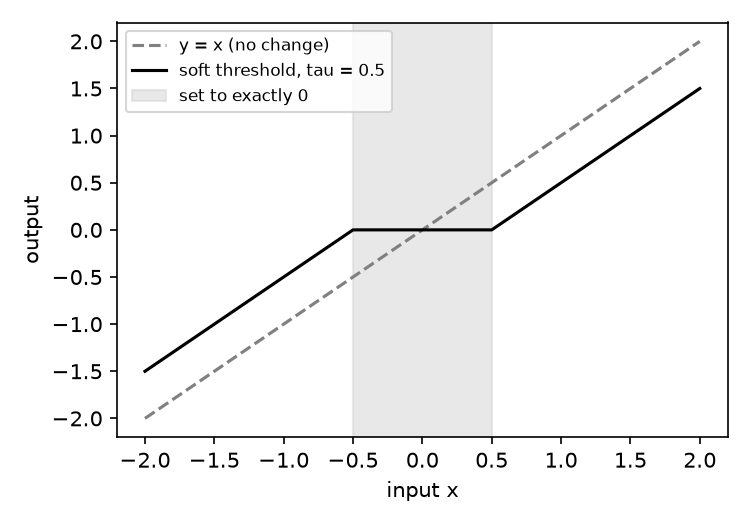

In [4]:
plot_soft_threshold_curve(0.5, FIGURES / "soft_threshold.png")
show_figure(FIGURES / "soft_threshold.png")

Inside the gray band, from −0.5 to 0.5, the output is 0. Outside the band, the black curve runs parallel to the dashed line $y = x$, at a distance of 0.5. The flat part in the middle is what creates exact zeros. A smooth penalty such as $x^2$ would only make values smaller, never exactly 0.

### 3.2 Singular value thresholding

For $g = \|\cdot\|_*$, the proximal operator is singular value thresholding (SVT). We write the singular value decomposition (SVD) $X = U \operatorname{diag}(\sigma)\, V^\top$. The columns of $U$ and $V$ are the singular vectors, and $\sigma$ holds the singular values. We soft-threshold the singular values and rebuild the matrix:

$$\operatorname{SVT}(X, \tau) = U \operatorname{diag}\big(\operatorname{soft}(\sigma, \tau)\big)\, V^\top.$$

Singular values below $\tau$ become 0, so the rank goes down.

We try it on the toy video of this notebook: 4 pixels and 3 frames, with one dancer. We describe it in detail in the next section. Here we only look at what SVT does to it, with $\tau = 0.5$.

In [5]:
background, dancer = make_toy_example()
toy_video = background + dancer

print_matrix("Singular values of the toy video:", singular_values(toy_video))
low_rank_version, new_singular_values = singular_value_threshold(toy_video, 0.5)
print_matrix("Singular values after SVT with tau = 0.5:", new_singular_values)
print_matrix("Rebuilt matrix (rows = pixels, columns = frames):", low_rank_version)

Singular values of the toy video:
[1.977 0.482 0.   ]

Singular values after SVT with tau = 0.5:
[1.477 0.    0.   ]

Rebuilt matrix (rows = pixels, columns = frames):
[[0.35  0.384 0.385]
 [0.35  0.384 0.385]
 [0.284 0.312 0.312]
 [0.559 0.615 0.615]]



The toy video has two non-zero singular values: 1.977 and 0.482. SVT lowers both by 0.5. The first one becomes 1.477. The second one becomes 0. So the rebuilt matrix has rank 1: each column is a multiple of the same column.

But the answer is not the background we want. The values are shrunk: at pixel 1 in frame 1, 0.5 became 0.35. And the dancer is not removed: pixel 3 (row 3) is now about 0.3 in all three frames, while the studio is 0.2 there. SVT alone gives a low-rank matrix, but it mixes the dancer into it. We need the second block to take the dancer out.

## 4. Robust PCA on the toy example

Here we build the toy video and look at it. The studio has 4 pixels with values $b = (0.5,\ 0.5,\ 0.2,\ 0.8)$. The light changes a little from frame to frame: the brightness is 1.0, then 0.9, then 1.1. So the background in frame $t$ is $b$ times the brightness of frame $t$. In frame 2, a dancer passes over pixel 3 and adds +0.6.

Background (rank 1):
[[0.5  0.45 0.55]
 [0.5  0.45 0.55]
 [0.2  0.18 0.22]
 [0.8  0.72 0.88]]

Dancer (one non-zero):
[[0.  0.  0. ]
 [0.  0.  0. ]
 [0.  0.6 0. ]
 [0.  0.  0. ]]

Toy video M = background + dancer:
[[0.5  0.45 0.55]
 [0.5  0.45 0.55]
 [0.2  0.78 0.22]
 [0.8  0.72 0.88]]



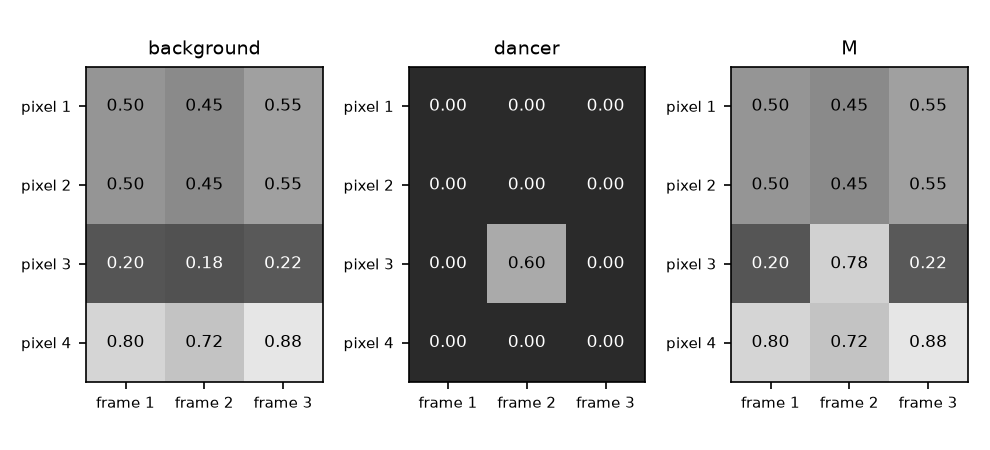

In [6]:
print_matrix("Background (rank 1):", background)
print_matrix("Dancer (one non-zero):", dancer)
print_matrix("Toy video M = background + dancer:", toy_video)

plot_small_matrices([background, dancer, toy_video], ["background", "dancer", "M"], FIGURES / "toy_video.png")
show_figure(FIGURES / "toy_video.png")

Each column of $M$ is one frame, and each row is one pixel. The dancer is the bright cell at pixel 3, frame 2: 0.78 instead of 0.18.

The background has rank 1, because every column is $b$ times a number. This is exactly the model $M = L + S$: a rank-1 $L$ plus an $S$ with a single non-zero.

### What the SVD sees

Here we compare the singular values of the background alone with the singular values of $M$.

In [7]:
print_matrix("Singular values of the background:", singular_values(background))
print_matrix("Singular values of M:", singular_values(toy_video))

Singular values of the background:
[1.888 0.    0.   ]

Singular values of M:
[1.977 0.482 0.   ]



The background has one non-zero singular value, 1.888. The other two are 0, up to rounding errors (about $10^{-17}$). This confirms that it has rank 1.

The single dancer pixel adds a second singular value of 0.482. One changed entry is enough to raise the rank from 1 to 2. This is why we cannot simply look for the rank-1 part of $M$: the dancer is part of what the SVD sees.

### Classic PCA smears the dancer

Classic PCA is the usual way to find a background. It keeps the best rank-1 approximation of $M$ in the least-squares sense: the first term of the SVD. We call it $L$, and we put the rest in $S = M - L$. This is our first baseline.

Classic PCA, L:
[[0.468 0.514 0.515]
 [0.468 0.514 0.515]
 [0.38  0.418 0.418]
 [0.749 0.823 0.824]]

Classic PCA, S = M - L:
[[ 0.032 -0.064  0.035]
 [ 0.032 -0.064  0.035]
 [-0.18   0.362 -0.198]
 [ 0.051 -0.103  0.056]]



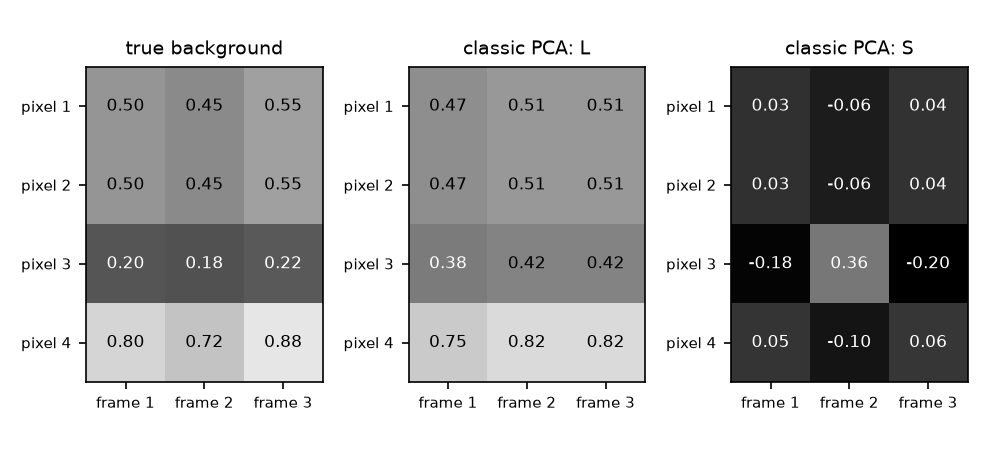

In [8]:
pca_background, pca_dancer = classic_pca(toy_video, rank=1)
print_matrix("Classic PCA, L:", pca_background)
print_matrix("Classic PCA, S = M - L:", pca_dancer)

plot_small_matrices([background, pca_background, pca_dancer], ["true background", "classic PCA: L", "classic PCA: S"],
                    FIGURES / "toy_classic_pca.png")
show_figure(FIGURES / "toy_classic_pca.png")

Classic PCA gets it wrong in two ways.

First, the dancer leaks into the background. At pixel 3, $L$ is about 0.38 to 0.42 in every frame, while the studio is only 0.18 to 0.22. The dancer has been spread over the three frames. It even changes the light: in $L$, frame 2 is brighter than frame 1 (0.51 against 0.47 at pixel 1), while the real light was dimmer in frame 2.

Second, the dancer leaks out of its own cell. $S$ is not sparse: every entry is non-zero. Pixel 3 in frame 2 keeps only 0.36 of the 0.6. The other pixels get small values between 0.03 and 0.10 in size, and pixel 3 gets about −0.2 in frames 1 and 3.

The reason is the squared error. Classic PCA minimizes $\|M - L\|_F^2$. A square punishes one large error much more than many small ones. So it prefers to spread the dancer's 0.6 over the whole matrix. We say that classic PCA smears the dancer into the background.

### Robust PCA: alternate the two thresholds

Proximal gradient descent minimizes $F(L, S)$ by repeating two moves.

1. A gradient step on the smooth part, $\tfrac{1}{2}\|M - L - S\|_F^2$. We compute the residual $R = M - L_k - S_k$, what is not yet explained. The gradient step adds half of it to each block: $L_k + \tfrac{1}{2}R$ and $S_k + \tfrac{1}{2}R$.
2. A proximal step on each penalty. SVT with threshold $\lambda_1 / 2$ on the $L$ block, and soft thresholding with threshold $\lambda_2 / 2$ on the $S$ block.

So one iteration is

$$L_{k+1} = \operatorname{SVT}\big(L_k + \tfrac{1}{2}R,\ \tfrac{\lambda_1}{2}\big), \qquad S_{k+1} = \operatorname{soft}\big(S_k + \tfrac{1}{2}R,\ \tfrac{\lambda_2}{2}\big).$$

Why a step of 1/2? The gradient of the smooth part is $(-R, -R)$. When $(L, S)$ moves, $R$ changes by the sum of the two moves, so the gradient changes at most 2 times as fast as the point. In the course, a step of 1 divided by this constant guarantees that $F$ never goes up.

The two operators work against each other. SVT pulls $L$ towards a low rank. Soft thresholding pulls $S$ towards a few large values. Each iteration gives the residual back to both, and the right split appears over time.

We start from $L = 0$ and $S = 0$. We use $\lambda_1 = 0.1$ and $\lambda_2 = 0.05$. Their ratio, 0.5, is $1/\sqrt{\max(n, T)}$ with $\max(n, T) = 4$ here, the ratio suggested by Candès et al. (2011). We stop when $F$ drops by less than $10^{-7}$ (in relative terms) between two iterations.

Robust PCA, L:
[[0.472 0.43  0.519]
 [0.472 0.43  0.519]
 [0.205 0.187 0.225]
 [0.755 0.688 0.831]]

Robust PCA, S:
[[0.    0.    0.   ]
 [0.    0.    0.   ]
 [0.    0.543 0.   ]
 [0.    0.    0.   ]]

Iterations: 161, rank of L: 1, non-zeros in S: 1
Relative error of L against the true background: 0.052


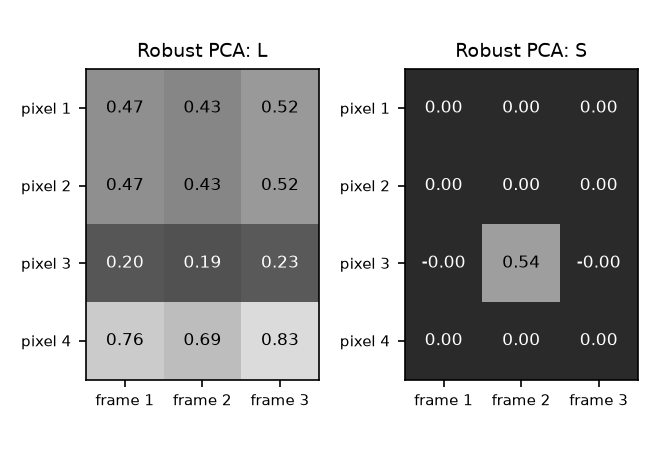

In [9]:
rpca_background, rpca_dancer, history = rpca_proximal_gradient(
    toy_video, config.TOY_LOW_RANK_WEIGHT, config.TOY_SPARSE_WEIGHT,
    config.RPCA_TOLERANCE, config.RPCA_MAX_ITERATIONS,
)
print_matrix("Robust PCA, L:", rpca_background)
print_matrix("Robust PCA, S:", rpca_dancer)
print(f"Iterations: {len(history['objective'])}, rank of L: {history['rank'][-1]}, non-zeros in S: {history['nonzeros'][-1]}")
print(f"Relative error of L against the true background: {relative_error(rpca_background, background):.3f}")

plot_small_matrices([rpca_background, rpca_dancer], ["Robust PCA: L", "Robust PCA: S"], FIGURES / "toy_robust_pca.png")
show_figure(FIGURES / "toy_robust_pca.png")

This time the split is right. $S$ has exactly one non-zero entry, at pixel 3 in frame 2. $L$ has rank 1, and at pixel 3 it stays close to the studio (0.19 to 0.23).

The answer is not perfect, and we can see why. The dancer is 0.543 instead of 0.6, and $L$ is about 5% too dark (relative error 0.052). Both thresholds shrink what they keep. This is the bias of the penalized problem that we saw with the five numbers in section 3.1. We will meet it again in the simulations.

### Does the objective go down?

Here we plot $F(L, S)$ at each iteration, and we check that it never goes up.

The objective never goes up: True
First iteration: 0.2733, last iteration: 0.2126


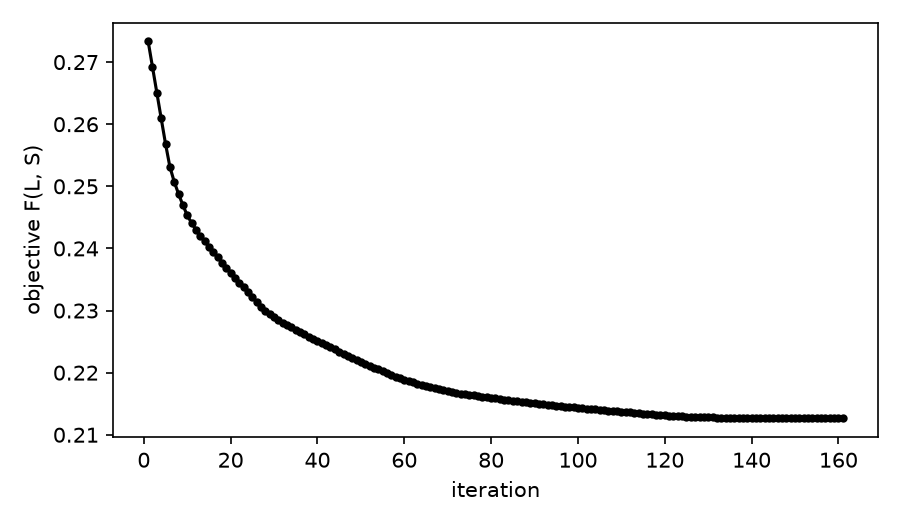

In [10]:
print(f"The objective never goes up: {objective_never_increases(history)}")
print(f"First iteration: {history['objective'][0]:.4f}, last iteration: {history['objective'][-1]:.4f}")

plot_history(history, "objective", "objective F(L, S)", FIGURES / "toy_objective.png")
show_figure(FIGURES / "toy_objective.png")

$F$ goes down at every iteration, from 0.2733 to 0.2126. It drops fast in the first 20 iterations, then more and more slowly. After about 130 iterations the curve is flat, and the stopping rule ends the run at iteration 161.

This is what the course promises for proximal gradient descent with a step of 1 over the Lipschitz constant. It is also a useful check of our code: a bug in one of the two operators would usually break it.

## 5. SDP check

Our solver is our own code. We want to check it against an independent solver. For this we use the semidefinite form of the nuclear norm:

$$\|L\|_* = \min_{W_1,\, W_2} \ \tfrac{1}{2}\big(\operatorname{tr} W_1 + \operatorname{tr} W_2\big) \quad \text{subject to} \quad \begin{pmatrix} W_1 & L \\ L^\top & W_2 \end{pmatrix} \succeq 0.$$

$W_1$ and $W_2$ are extra symmetric matrices. $\operatorname{tr}$ is the trace, the sum of the diagonal. $\succeq 0$ means that the big block matrix is positive semidefinite: all its eigenvalues are at least 0. So our problem can be written as a semidefinite program (SDP), a standard convex problem.

The library CVXPY does this rewriting for us (`cp.normNuc`). It then calls a general conic solver; here it picks SCS. We solve the same penalized problem on a random 30 × 30 matrix (rank 2, 5% of the entries corrupted, $\lambda_1 = 0.1$, $\lambda_2 = \lambda_1/\sqrt{30}$) with both, and compare the answers.

From here on, our solver is FISTA. It is the accelerated proximal gradient method of the course. It takes exactly the same step as above, but from a point pushed a little further in the direction of the last move. In our tests it needed 3 to 6 times fewer iterations and reached the same objective. Its objective can go up for a step, so it stops when $L$ changes by less than a small amount instead. For this check, we make both solvers run to a tight tolerance, so we compare their optima and not their stopping rules.

In [11]:
check = compare_with_cvxpy(config.SDP_CHECK_SIZE, config.SDP_CHECK_RANK, config.SDP_CHECK_SPARSITY,
                           config.RANDOM_SEED, config.SDP_CHECK_TOLERANCE, config.SDP_CHECK_MAX_ITERATIONS)
print(f"CVXPY solver: {check['solver']}")
print(f"Our objective:   {check['our_objective']:.7f}")
print(f"CVXPY objective: {check['cvxpy_objective']:.7f}")
print(f"Relative gap between the objectives: {check['objective_gap']:.1e}")
print(f"Relative difference between the two L: {check['low_rank_difference']:.1e}, between the two S: {check['sparse_difference']:.1e}")

CVXPY solver: SCS
Our objective:   1.6505721
CVXPY objective: 1.6505737
Relative gap between the objectives: 9.9e-07
Relative difference between the two L: 2.5e-06, between the two S: 2.8e-06


The two solvers agree. Their objectives differ by about $10^{-6}$ in relative terms, and so do their $L$ and $S$. Our objective is even slightly lower than the one of CVXPY. This means that SCS stops a little before the exact optimum, not that our solver is off.

So our code solves the convex problem we wrote down. This matters, because from now on we trust its answers on matrices far too large for CVXPY.

### Run times

Here we time both solvers on square matrices from 20 × 20 to 100 × 100, with the same settings. The CVXPY time includes the rewriting into an SDP. Run times change a little from one run to the next.

SDP check: size 20 x 20...


SDP check: size 40 x 40...


SDP check: size 60 x 60...


SDP check: size 80 x 80...


SDP check: size 100 x 100...


Sizes:                 [ 20  40  60  80 100]
Our time (s):          [0.025 0.055 0.114 0.168 0.223]
CVXPY time (s):        [0.04  0.119 0.268 0.449 0.687]
CVXPY time / our time: [1.6 2.2 2.3 2.7 3.1]


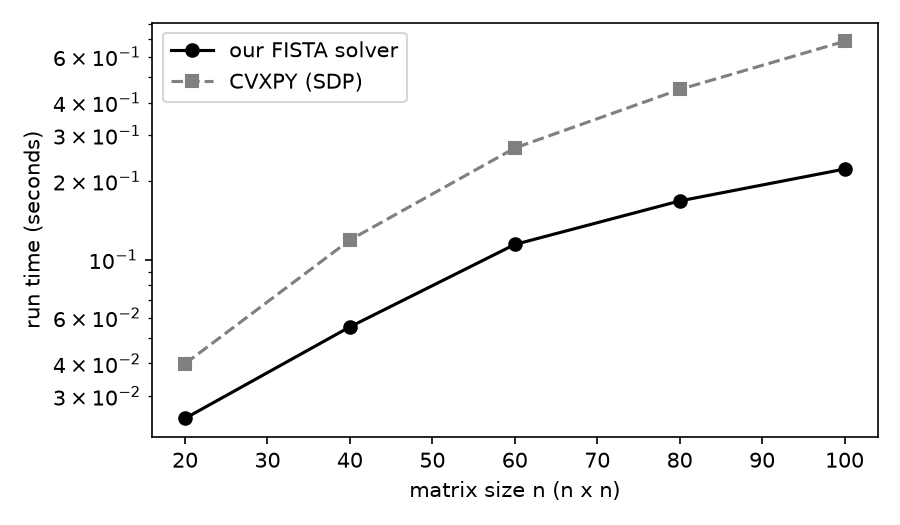

In [12]:
timings = time_both_solvers(config.SDP_TIMING_SIZES, config.SDP_CHECK_RANK, config.SDP_CHECK_SPARSITY,
                            config.RANDOM_SEED, config.SDP_CHECK_TOLERANCE, config.SDP_CHECK_MAX_ITERATIONS)
print("Sizes:                ", timings["sizes"])
print("Our time (s):         ", np.round(timings["our_time"], 3))
print("CVXPY time (s):       ", np.round(timings["cvxpy_time"], 3))
print("CVXPY time / our time:", np.round(timings["cvxpy_time"] / timings["our_time"], 1))

plot_solver_times(timings, FIGURES / "sdp_timings.png")
show_figure(FIGURES / "sdp_timings.png")

Both run times grow with the size, and CVXPY is slower at every size. In our runs it was between about 1.5 and 4 times slower, and the gap grows with $n$. The exact values change a little each time we run the cell.

At these small sizes our solver is not much faster. The real difference comes with the video. There, $M$ has 14,400 rows and 400 columns, so the block matrix of the SDP would be 14,800 × 14,800. We did not try CVXPY at that size. Our solver only needs one SVD of a matrix the size of $M$ per iteration. On our laptop, one iteration on the video took between 0.3 and 1.2 seconds, depending on the state of the machine.

## 6. Simulations and the success map

Robust PCA cannot work in every case. If $L$ has a high rank, or if too many entries are corrupted, the split $M = L + S$ is no longer unique. Here we measure where it works, on random matrices where we know the right answer.

We build $n \times n$ matrices with $n = 100$. The low-rank part is $L_0 = U V^\top / \sqrt{n}$, where $U$ and $V$ are random Gaussian matrices with $r$ columns, so $L_0$ has rank $r$. The sparse part $S_0$ has each entry non-zero with probability $\rho$, with a random value of +1 or −1. We solve the penalized problem for $M = L_0 + S_0$ with $\lambda_1 = 0.1$ and $\lambda_2 = \lambda_1/\sqrt{n} = 0.01$.

The grid has 9 values of the rank ratio $r/n$ and 9 values of the sparsity $\rho$, both from 0.02 to 0.4, with 3 trials per cell. That is 243 runs. They take about 5 minutes, so we load the saved results.

**What counts as a success?** Exact recovery is not possible here, because SVT lowers each of the $r$ singular values by about $\lambda_1$. Even a perfect answer is off by about $\lambda_1\sqrt{r}$ (the shrinkage bias). So a trial is a success when $\|\hat L - L_0\|_F < 3\,\lambda_1\sqrt{r}$ and $\hat L$ has the right rank $r$. Classic PCA is given the true rank, so for it only the error condition applies.

Loading saved simulation grid: simulation_results.npz


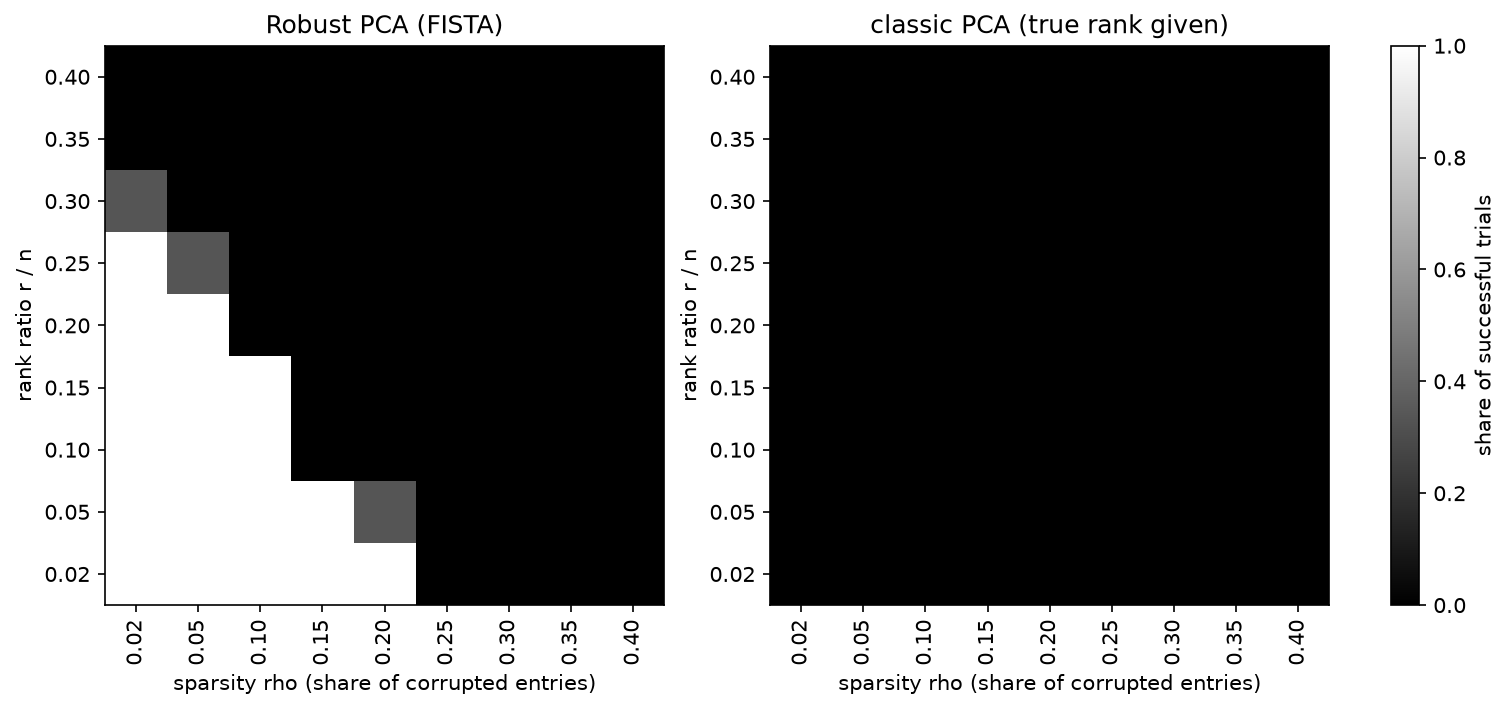

In [13]:
simulation_results = simulation_grid(config)
rpca_map, pca_map = success_fraction(simulation_results, config.SIMULATION_LOW_RANK_WEIGHT, config.SIMULATION_SUCCESS_FACTOR)
plot_success_maps([rpca_map, pca_map], ["Robust PCA (FISTA)", "classic PCA (true rank given)"],
                  simulation_results["rank_ratios"], simulation_results["sparsities"], FIGURES / "phase_transition.png")
show_figure(FIGURES / "phase_transition.png")

This is a phase transition diagram. Each cell is one pair (rank ratio, sparsity). White means that all 3 trials succeeded, black that all failed.

On the left, Robust PCA succeeds in the bottom-left corner: low rank and few corruptions. With a rank ratio of 0.02, it succeeds up to $\rho = 0.2$, so up to one corrupted entry in five. With $\rho = 0.02$, it succeeds up to a rank ratio of 0.25. When both grow, the success region ends quickly, along a diagonal border. Outside it, the corruptions and the low-rank part can no longer be told apart.

On the right, classic PCA fails everywhere, even with the true rank and only 2% corruptions. This is the smearing of the toy example, at a larger scale.

Here we count the successes and look at how far classic PCA is from the threshold.

In [14]:
summary = summarize_success(simulation_results, config.SIMULATION_LOW_RANK_WEIGHT, config.SIMULATION_SUCCESS_FACTOR)
print(f"Robust PCA: {summary['rpca_successful_trials']} successful trials out of {summary['trials']}")
print(f"Robust PCA: all 3 trials succeed in {summary['rpca_full_cells']} cells out of {summary['cells']}")
print(f"Classic PCA: {summary['pca_successful_trials']} successful trials out of {summary['trials']}")
print(f"Classic PCA error / shrinkage bias: median {summary['pca_median_error_ratio']:.1f}, smallest {summary['pca_smallest_error_ratio']:.1f}")
print(f"Robust PCA run time: {summary['total_run_time']:.0f} s in total, {summary['largest_run_time']:.2f} s for the longest run")

Robust PCA: 57 successful trials out of 243
Robust PCA: all 3 trials succeed in 18 cells out of 81
Classic PCA: 0 successful trials out of 243
Classic PCA error / shrinkage bias: median 69.6, smallest 17.7
Robust PCA run time: 307 s in total, 2.73 s for the longest run


Robust PCA succeeds in 57 of the 243 trials, and in all 3 trials of 18 cells out of 81. Classic PCA succeeds in none. Its error is at least 17.7 times the shrinkage bias, and 69.6 times in the median trial. So classic PCA does not just miss the threshold by a little.

Our success region is smaller than in Candès et al. (2011). We expected this. Our matrices are small ($n = 100$), and the penalty $\lambda_1 = 0.1$ adds a bias that the constrained problem of the paper does not have.

### Does the map depend on the factor 3?

The factor 3 in the success rule is our choice. Here we draw the same map with factors 2, 3 and 5, from the same 243 runs.

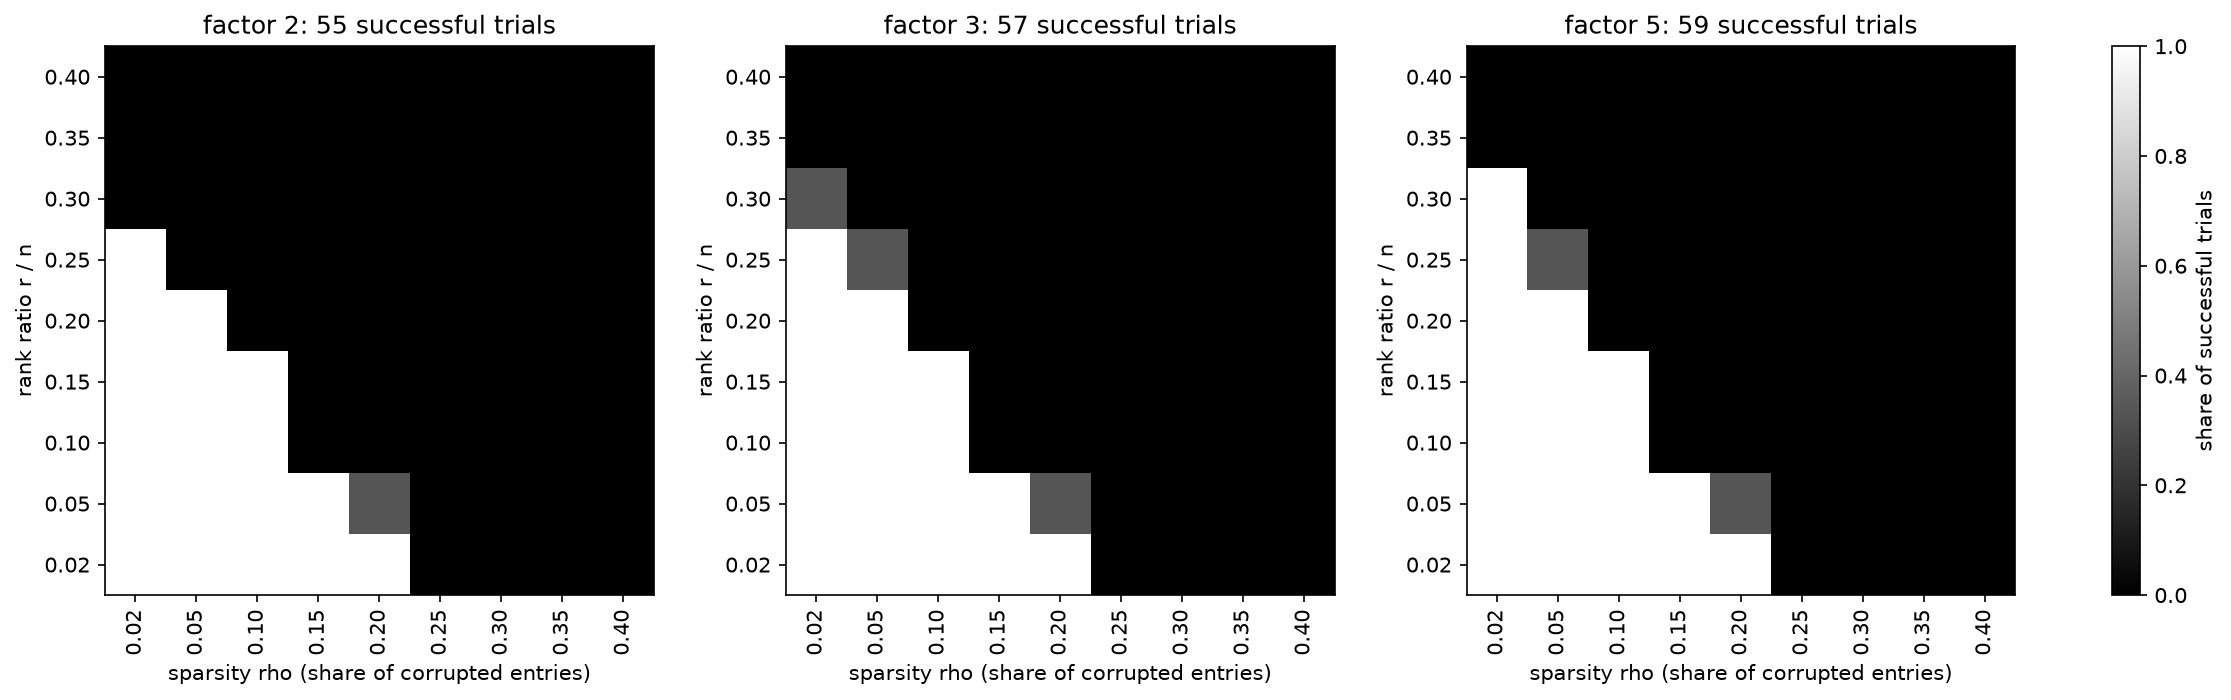

In [15]:
sensitivity_maps = []
sensitivity_titles = []
for factor in config.SENSITIVITY_FACTORS:
    factor_map, _ = success_fraction(simulation_results, config.SIMULATION_LOW_RANK_WEIGHT, factor)
    factor_summary = summarize_success(simulation_results, config.SIMULATION_LOW_RANK_WEIGHT, factor)
    sensitivity_maps.append(factor_map)
    sensitivity_titles.append(f"factor {factor}: {factor_summary['rpca_successful_trials']} successful trials")

plot_success_maps(sensitivity_maps, sensitivity_titles, simulation_results["rank_ratios"], simulation_results["sparsities"],
                  FIGURES / "phase_transition_sensitivity.png")
show_figure(FIGURES / "phase_transition_sensitivity.png")

The three maps are almost the same: 55, 57 and 59 successful trials. Only a few cells on the border change. With factor 5, every trial with the right rank already counts as a success, so the rank condition does most of the work. The shape of the success region does not depend on our choice of factor.

This closes the first half of part 1. We know that our solver solves the right convex problem, and where it can recover a low-rank plus sparse split. Next, we run it on the real video.